In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/car data.csv")


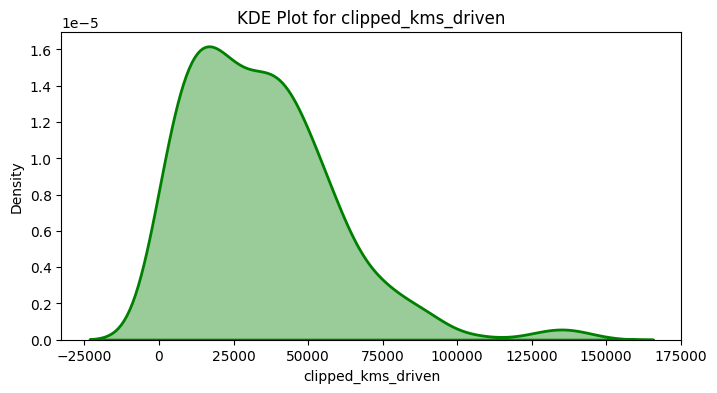

In [4]:
kms_threshold = df["Kms_Driven"].quantile(0.99)
df = df[df["Kms_Driven"] <= kms_threshold]

plt.figure(figsize = (8,4))
sns.kdeplot(x = "Kms_Driven", data = df, fill=True, linewidth = 2, alpha = 0.4, color = "green")
plt.title(f"KDE Plot for clipped_kms_driven")
plt.xlabel("clipped_kms_driven")
plt.show()

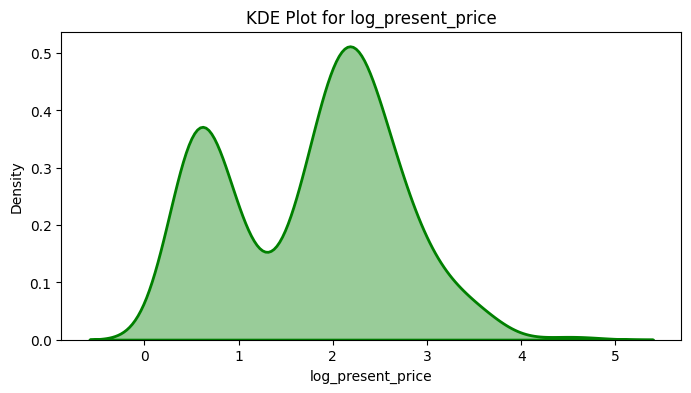

In [5]:
df["log_present_price"] = np.log1p(df["Present_Price"])

plt.figure(figsize = (8,4))
sns.kdeplot(x = "log_present_price", data = df, fill=True, linewidth = 2, alpha = 0.4, color = "green")
plt.title(f"KDE Plot for log_present_price")
plt.xlabel("log_present_price")
plt.show()

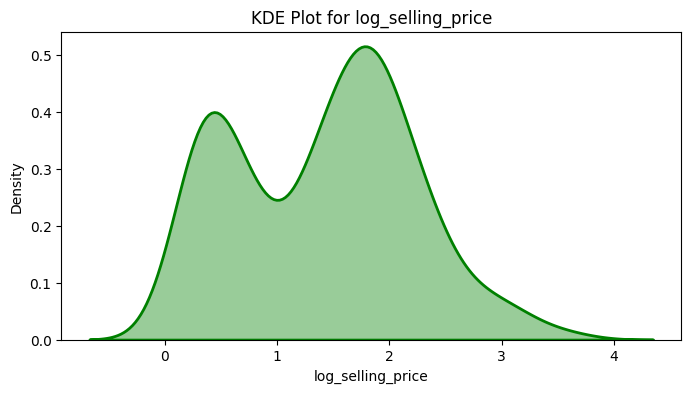

In [6]:
df["log_selling_price"] = np.log1p(df["Selling_Price"])

plt.figure(figsize = (8,4))
sns.kdeplot(x = "log_selling_price", data = df, fill=True, linewidth = 2, alpha = 0.4, color = "green")
plt.title(f"KDE Plot for log_selling_price")
plt.xlabel("log_selling_price")
plt.show()

count    296.000000
mean      12.324324
std        2.840903
min        8.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       23.000000
Name: Car_Age, dtype: float64


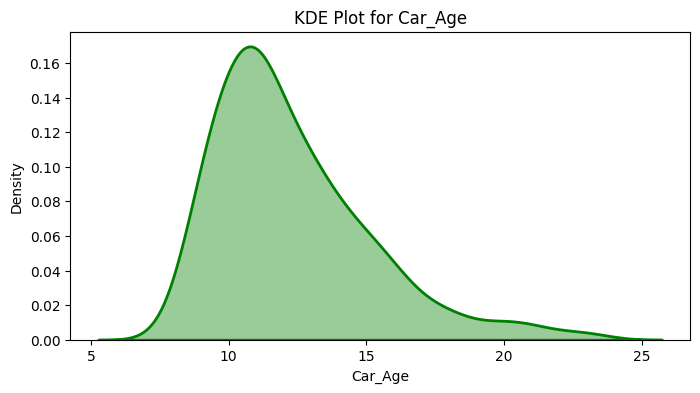

In [10]:
df["Car_Age"] = 2026 - df["Year"]

df.drop(columns = ["Year"])
print(df["Car_Age"].describe())

plt.figure(figsize = (8,4))
sns.kdeplot(x = "Car_Age", data = df, fill=True, linewidth = 2, alpha = 0.4, color = "green")
plt.title(f"KDE Plot for Car_Age")
plt.xlabel("Car_Age")
plt.show()


In [14]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ["Fuel_Type", "Seller_Type", "Transmission"]
encoder = OneHotEncoder(drop = 'first', sparse_output = False)
encoded_array = encoder.fit_transform(df[cat_cols])
encoded_cols = encoder.get_feature_names_out(cat_cols)
df_encoded = pd.DataFrame(encoded_array, columns = encoded_cols, index = df.index)

df.drop(columns = cat_cols, inplace=True)
df = pd.concat([df, df_encoded], axis=1)

In [16]:
df.drop(columns = ['Car_Name', 'Year', 'Selling_Price', 'Present_Price'], inplace=True)

In [18]:
df.to_csv("../data/engineered_car_data.csv", index=False)

In [22]:
y = df["log_selling_price"]

X = df.drop(columns=["log_selling_price"])

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
print(f"No. of cars in train = {X_train.shape[0]}")
print(f"No. of cars in test = {X_test.shape[0]}")

No. of cars in train = 236
No. of cars in test = 60


In [28]:
from sklearn.preprocessing import StandardScaler

scale_cols = ["Kms_Driven", "Car_Age", "log_present_price"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])

X_test_scaled = X_test.copy()
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print(X_train_scaled[scale_cols].head())

     Kms_Driven   Car_Age  log_present_price
63    -1.100945 -1.157334           2.086528
17     0.058531 -0.477904           0.024226
218    0.175972 -1.157334          -0.106439
222    0.085965  0.201526           0.633824
185   -0.079034  0.201526          -1.564292


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

model = LinearRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print(f"R2 Score: {r2_score(y_test, y_pred)}")
print(f"MSE Score: {mean_squared_error(y_test, y_pred)}")

R2 Score: 0.9708454420605319
MSE Score: 0.0197820008256687


In [31]:
coefficients = pd.DataFrame({
    "Features" : X_train_scaled.columns,
    "Weight (Coefficient)" : model.coef_
})

print(f"Intercept: {model.intercept_}")

coefficients['Abs_Weight'] = coefficients['Weight (Coefficient)'].abs()
coefficients = coefficients.sort_values(by='Abs_Weight', ascending=False).drop(columns = ['Abs_Weight'])
print(coefficients.to_string(index=False))

Intercept: 1.3483452751828404
              Features  Weight (Coefficient)
     log_present_price              0.712336
      Fuel_Type_Diesel              0.274944
               Car_Age             -0.152237
      Fuel_Type_Petrol              0.101705
                 Owner             -0.097680
            Kms_Driven             -0.087548
Seller_Type_Individual             -0.066746
   Transmission_Manual             -0.041105


In [34]:
import joblib
import os

os.makedirs('../models', exist_ok = True)

joblib.dump(model, '../models/linear_regression_model.pkl')
joblib.dump(scaler, '../models/feature_scaler.pkl')
joblib.dump(encoder, '../models/categorical_encoder.pkl')

print("Successfully saved model, scaler, encoder to the 'models' folder")

Successfully saved model, scaler, encoder to the 'models' folder
